In [22]:
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split

In [23]:
apartments_df = pd.read_csv("streeteasy.csv")

numerical_features = ['bedrooms', 'bathrooms', 'size_sqft', 'min_to_subway', 'floor', 'building_age_yrs',
                      'no_fee', 'has_roofdeck', 'has_washer_dryer', 'has_doorman', 'has_elevator', 'has_dishwasher',
                      'has_patio', 'has_gym']

# create tensor of input features
X = torch.tensor(apartments_df[numerical_features].values, dtype=torch.float)
# create tensor of targets
y = torch.tensor(apartments_df['rent'].values, dtype=torch.float).view(-1,1)

X_train, X_test, y_train, y_test = train_test_split(X, y,
    train_size=0.80,
    test_size=0.20,
    random_state=2) 

In [24]:
# set a random seed - do not modify
torch.manual_seed(42)

# Define the model using nn.Sequential
model = nn.Sequential(
    nn.Linear(14, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

# MSE loss function + optimizer
loss = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 20000
for epoch in range(num_epochs):
    predictions = model(X_train) 
    MSE = loss(predictions, y_train) 
    MSE.backward()
    optimizer.step() 
    optimizer.zero_grad()
    
    ## DO NOT MODIFY ##
    # keep track of the loss during training
    if (epoch + 1) % 1000 == 0:
        print(f'Epoch [{epoch + 1}/{num_epochs}], MSE Loss: {MSE.item()}')

torch.save(model.state_dict(), 'model.pth')

Epoch [1000/20000], MSE Loss: 2685170.5
Epoch [2000/20000], MSE Loss: 2533362.25
Epoch [3000/20000], MSE Loss: 2333036.25
Epoch [4000/20000], MSE Loss: 2060779.375
Epoch [5000/20000], MSE Loss: 1979804.875
Epoch [6000/20000], MSE Loss: 1929706.625
Epoch [7000/20000], MSE Loss: 1891925.75
Epoch [8000/20000], MSE Loss: 1865022.125
Epoch [9000/20000], MSE Loss: 1845033.625
Epoch [10000/20000], MSE Loss: 1824269.75
Epoch [11000/20000], MSE Loss: 1806794.625
Epoch [12000/20000], MSE Loss: 1785050.75
Epoch [13000/20000], MSE Loss: 1769454.125
Epoch [14000/20000], MSE Loss: 1754166.25
Epoch [15000/20000], MSE Loss: 1744374.0
Epoch [16000/20000], MSE Loss: 1734886.0
Epoch [17000/20000], MSE Loss: 1723677.5
Epoch [18000/20000], MSE Loss: 1716755.25
Epoch [19000/20000], MSE Loss: 1704147.25
Epoch [20000/20000], MSE Loss: 1697352.125


In [25]:
# Recreate the model architecture exactly as in Cell 3
model = nn.Sequential(
    nn.Linear(14, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

# Load weights safely (PyTorch 2.6+ default)
state_dict = torch.load("model.pth", weights_only=True)
model.load_state_dict(state_dict)

model.eval()
with torch.no_grad():
    predictions = model(X_test)
    test_MSE = loss(predictions, y_test)

print('Test MSE is ' + str(test_MSE.item()))
print('Test Root MSE is ' + str(test_MSE.item()**0.5))

Test MSE is 1863160.5
Test Root MSE is 1364.976373421899


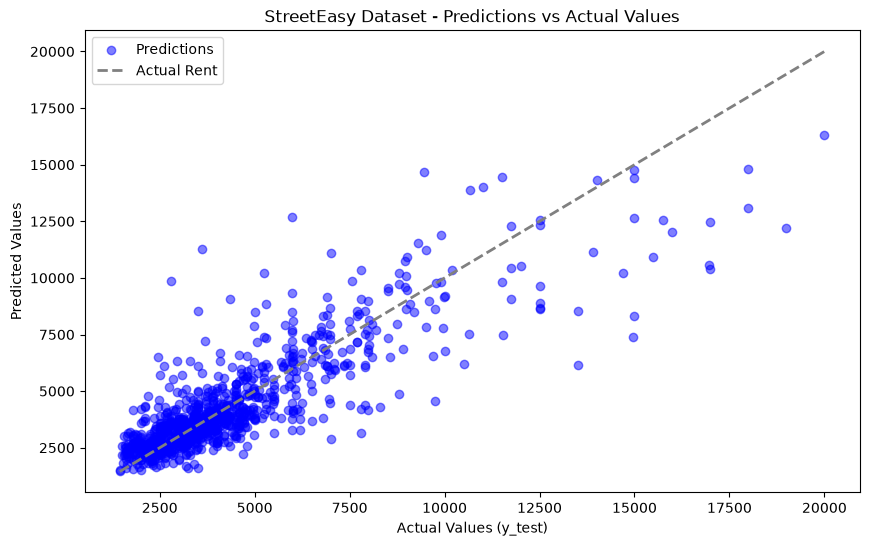

In [26]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(10, 6))
plt.scatter(y_test, predictions, label='Predictions', alpha=0.5, color='blue')

plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values')

plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='gray', linewidth=2,
         label="Actual Rent")
plt.legend()
plt.title('StreetEasy Dataset - Predictions vs Actual Values')
plt.show()